## Introducción



In [1]:
import sys
import os

sys.path.append(os.path.abspath("../src"))

import pandas as pd
import matplotlib.pyplot as plt
import unicodedata
import numpy as np
from scipy.stats import spearmanr
import openpyxl
from data_processing import *
from montecarlo import*
from sensitivity import*
from uncertainty import*

path_results="C:/Users/Pame/Desktop/carbon_uncertainty/results/"

In [2]:
if __name__ == "__main__":
    FILE_ACTIVITY = "C:/Users/Pame/Desktop/carbon_uncertainty/data/data_activity.xlsx"
    FILE_UNCERTAINTY = "C:/Users/Pame/Desktop/carbon_uncertainty/data/uncertainty_dist_act_FE.xlsx"
    SEED=12345
    N_ITER = 200000
    
    df, sin_match, discrepancias = construir_dataframe(
    FILE_ACTIVITY,
    FILE_UNCERTAINTY
)

df = afinar_fe_group(df)

df["emision_central_kg"] = (
    df["fe_central"].fillna(0) * df["cantidad"].fillna(0)
)

df["emision_central_tn"] = df["emision_central_kg"] / 1000

afinar_fe_group: se fusionaron 2 conjuntos de fe_group que compartían el mismo valor numérico de FE bajo nombres distintos:
  -> 'guantes de trabajo'  (fusiona: ['guantes de trabajo', 'ropa de trabajo (conjunto)'])
  -> 'productos de limpieza'  (fusiona: ['productos de limpieza', 'resmas de papel a4'])


In [37]:
N_ITER = 200_000
SEED = 14

# Monte Carlo con FE independientes
rng_naive = np.random.default_rng(SEED)

emis_naive = simular_montecarlo(
    df,
    N_ITER,
    rng_naive,
    correlacionar_fe=False
)

# Monte Carlo con FE correlacionados
rng_corr = np.random.default_rng(SEED)

emis_corr = simular_montecarlo(
    df,
    N_ITER,
    rng_corr,
    correlacionar_fe=True
)

In [38]:
# Emisiones centrales por actividad
# Las cantidades simuladas y los factores de emisión
# se expresan de modo que el producto resulte en kg CO2e.
df = df.copy()

df["emision_central_kg"] = (
    df["cantidad"].fillna(0) * df["fe_central"].fillna(0)
)

df["emision_central_tn"] = df["emision_central_kg"] / 1000

# Para asegurar que la posición de cada fila coincida
# con la columna correspondiente de las matrices:
df = df.reset_index(drop=True)

assert emis_naive.shape[1] == len(df)
assert emis_corr.shape[1] == len(df)

## Composición del inventario: emisiones por fuente
El objetivo es identificar qué actividades explican la mayor parte de las emisiones centrales del inventario. Para que el gráfico sea legible se agruparon las fuentes menores a 3% en “Otras fuentes”.

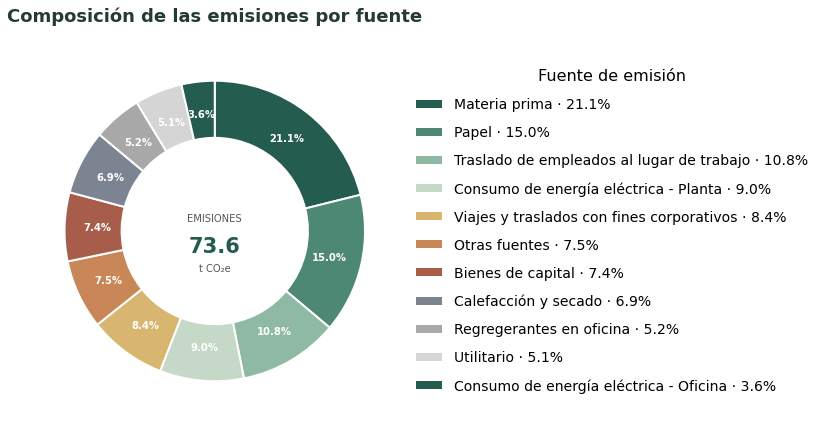

In [31]:
# --------------------------------------------------
# 1. Preparar y agregar los datos por fuente
# --------------------------------------------------

if "emision_central_tn" not in df.columns:
    df["emision_central_tn"] = (
        df["cantidad"].fillna(0) * df["fe_central"].fillna(0) / 1000
    )

emisiones_fuente = (
    df.assign(fuente=df["fuente"].fillna("Sin especificar"))
      .groupby("fuente", as_index=False)["emision_central_tn"]
      .sum()
      .sort_values("emision_central_tn", ascending=False)
)

# Conservar únicamente emisiones positivas
emisiones_fuente = emisiones_fuente[
    emisiones_fuente["emision_central_tn"] > 0
].copy()

total_tn = emisiones_fuente["emision_central_tn"].sum()

if total_tn <= 0:
    raise ValueError("No hay emisiones positivas para graficar.")

# Calcular contribución porcentual
emisiones_fuente["porcentaje"] = (
    emisiones_fuente["emision_central_tn"] / total_tn * 100
)

# --------------------------------------------------
# 2. Agrupar fuentes con contribución < 3% en "Otras"
# --------------------------------------------------

umbral = 3

fuentes_principales = emisiones_fuente[
    emisiones_fuente["porcentaje"] >= umbral
].copy()

fuentes_menores = emisiones_fuente[
    emisiones_fuente["porcentaje"] < umbral
]

if not fuentes_menores.empty:
    otras = pd.DataFrame({
        "fuente": ["Otras fuentes"],
        "emision_central_tn": [
            fuentes_menores["emision_central_tn"].sum()
        ],
        "porcentaje": [
            fuentes_menores["porcentaje"].sum()
        ]
    })

    emisiones_grafico = pd.concat(
        [fuentes_principales, otras],
        ignore_index=True
    )
else:
    emisiones_grafico = fuentes_principales.copy()

# Ordenar de mayor a menor contribución
emisiones_grafico = emisiones_grafico.sort_values(
    "emision_central_tn",
    ascending=False
).reset_index(drop=True)

# --------------------------------------------------
# 3. Gráfico de dona
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 7), facecolor="white")
ax.set_facecolor("white")

colores_base = [
    "#245C4F", "#4D8875", "#8DB9A5", "#C6D9C9",
    "#D9B66F", "#C98758", "#A85D4B", "#7D8491",
    "#A8A8A8", "#D5D5D5"
]

colores = [
    colores_base[i % len(colores_base)]
    for i in range(len(emisiones_grafico))
]

def mostrar_porcentaje(pct):
    return f"{pct:.1f}%" if pct >= 3 else ""

wedges, _, _ = ax.pie(
    emisiones_grafico["emision_central_tn"],
    startangle=90,
    counterclock=False,
    colors=colores,
    labels=None,
    autopct=mostrar_porcentaje,
    pctdistance=0.78,
    wedgeprops={
        "width": 0.38,
        "edgecolor": "white",
        "linewidth": 2
    },
    textprops={
        "fontsize": 10,
        "color": "white",
        "weight": "bold"
    }
)

# Centro de la dona
ax.text(
    0, 0.08, "EMISIONES",
    ha="center", va="center",
    fontsize=10, color="#555555"
)
ax.text(
    0, -0.10, f"{total_tn:,.1f}",
    ha="center", va="center",
    fontsize=21, fontweight="bold", color="#245C4F"
)
ax.text(
    0, -0.25, "t CO₂e",
    ha="center", va="center",
    fontsize=10, color="#555555"
)

# Leyenda
etiquetas = [
    f"{fila.fuente} · {fila.porcentaje:.1f}%"
    for fila in emisiones_grafico.itertuples()
]

ax.legend(
    wedges,
    etiquetas,
    title="Fuente de emisión",
    loc="center left",
    bbox_to_anchor=(1.00, 0.5),
    frameon=False,
    fontsize=14,
    title_fontsize=16,
    labelspacing=1.0
)

ax.set_title(
    "Composición de las emisiones por fuente",
    fontsize=18,
    fontweight="bold",
    color="#263A35",
    pad=22
)

ax.set_aspect("equal")
plt.tight_layout()

plt.savefig(
    path_results +"emisiones_por_fuente.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="none"#fondo transparente
)
plt.savefig(
    path_results +"emisiones_por_fuente.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


## Distribuciones Monte Carlo: independiente vs. correlacionado
Permite ver cómo cambia la distribución de la emisión total cuando se consideran los factores de emisión compartidos.
En la función `simular_montecarlo`, la matriz contiene emisiones por actividad en kg. Por eso, al sumar las columnas, se convirtió el resultado a toneladas.

In [39]:
resumen_ipcc = propagacion_analitica(df)
print(resumen_ipcc)

{'media': 73.55730794571001, 'sd': 4.657625516508434, 'p2_5': 64.42852960787206, 'p50': 73.55730794571001, 'p97_5': 82.68608628354795}


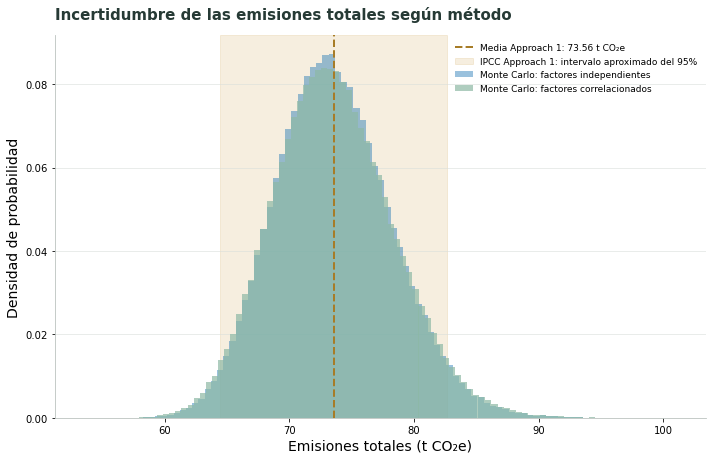

In [50]:
# Emisiones totales simuladas, en toneladas
total_naive = emis_naive.sum(axis=1) / 1000
total_corr = emis_corr.sum(axis=1) / 1000

# Resumen de Approach 1

ipcc_media = resumen_ipcc["media"]
ipcc_inf = resumen_ipcc["p2_5"]
ipcc_sup = resumen_ipcc["p97_5"]

# Paleta del gráfico de dona
verde_oscuro = "#245C4F"
verde_medio = "#4D8875"
verde_salvia = "#8DB9A5"
dorado = "#D9B66F"
gris_claro = "#D9DEDB"

fig, ax = plt.subplots(figsize=(10, 6.5), facecolor="white")
ax.set_facecolor("white")

# Nota con intervalos centrales del 95%
nota = (
    f"Independiente: [{q_naive[0]:.2f}, {q_naive[1]:.2f}]\n"
    f"Correlacionado: [{q_corr[0]:.2f}, {q_corr[1]:.2f}]"
)
# Intervalo de Approach 1: banda de referencia
ax.axvspan(
    ipcc_inf, ipcc_sup,
    color=dorado, alpha=0.22,
    label="IPCC Approach 1: intervalo aproximado del 95%",
    zorder=0
)

# Distribuciones Monte Carlo
ax.hist(
    total_naive, bins=90, density=True, alpha=0.45,
#    edgecolor="none",
    label="Monte Carlo: factores independientes"
)

ax.hist(
    total_corr, bins=90, density=True,     
    color=verde_salvia,alpha=0.70,
#    edgecolor="none",
    label="Monte Carlo: factores correlacionados"
)

# Media de Approach 1
ax.axvline(
    ipcc_media, color="#A77C27",
    linestyle="--", linewidth=2,
    label=f"Media Approach 1: {ipcc_media:.2f} t CO₂e"
)

ax.set_title(
    "Incertidumbre de las emisiones totales según método",
    fontsize=15, fontweight="bold",
    color="#263A35", loc="left", pad=16
)
ax.set_xlabel("Emisiones totales (t CO₂e)", fontsize=14)
ax.set_ylabel("Densidad de probabilidad", fontsize=14)

ax.grid(axis="y", color=gris_claro, linewidth=0.8, alpha=0.7)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#B8C0BC")
ax.spines["bottom"].set_color("#B8C0BC")

ax.legend(frameon=False, fontsize=9, loc="upper right")

plt.tight_layout()
plt.savefig(
    path_results +"comparacion_ipcc_montecarlo.png",
    dpi=300, bbox_inches="tight", facecolor="none"
)
plt.savefig(
    path_results+"comparacion_ipcc_montecarlo.pdf",
    bbox_inches="tight", facecolor="white"
)
plt.show()

In [42]:
amplitud_naive = (
    np.percentile(total_naive, 97.5)
    - np.percentile(total_naive, 2.5)
)

amplitud_corr = (
    np.percentile(total_corr, 97.5)
    - np.percentile(total_corr, 2.5)
)

cambio_pct = (
    (amplitud_corr - amplitud_naive) / amplitud_naive * 100
)

print(f"Amplitud MC independiente: {amplitud_naive:.2f} t CO₂e")
print(f"Amplitud MC correlacionado: {amplitud_corr:.2f} t CO₂e")
print(f"Cambio relativo de amplitud: {cambio_pct:.1f}%")

Amplitud MC independiente: 18.29 t CO₂e
Amplitud MC correlacionado: 18.85 t CO₂e
Cambio relativo de amplitud: 3.1%


In [58]:
print(np.percentile(total_corr, 97.5))
print(np.percentile(total_corr, 2.5))

83.556561088562
64.70498142242432


In [46]:
tabla_sens = sensibilidad(df, emis_corr)

display(
    tabla_sens[
        [
            "actividad",
            "emision_media_pct_total",
            "contribucion_incertidumbre_pct",
            "indice_riesgo",
        ]
    ].head(10).round(2)
)

,actividad,emision_media_pct_total,contribucion_incertidumbre_pct,indice_riesgo
30,Camión HGV 30 tn,14.99,32.94,2.20
17,Papel,12.74,18.93,1.49
41,Auto particular,9.42,15.30,1.62
22,Computadora DELL,6.37,8.59,1.35
18,HDPE,6.29,4.62,0.73
39,Auto particular,2.48,3.11,1.25
37,RSU,2.60,2.91,1.12
38,Avión nacional,4.36,2.87,0.66
4,R-410A,5.23,2.75,0.52
5,Energía eléctrica Argentina,9.04,2.64,0.29


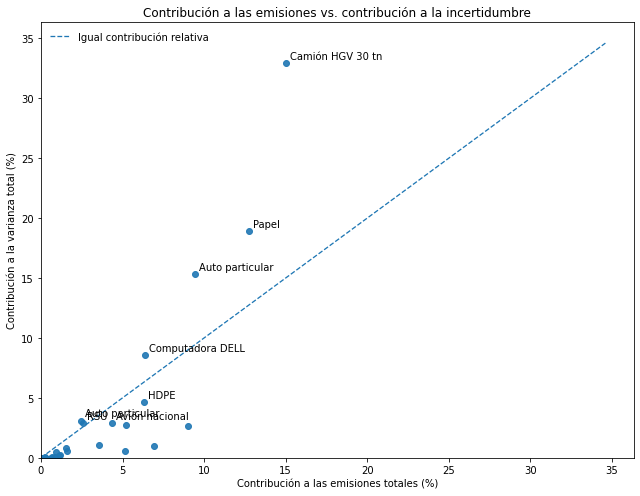

In [52]:
fig, ax = plt.subplots(figsize=(9, 7))

x = tabla_sens["emision_media_pct_total"]
y = tabla_sens["contribucion_incertidumbre_pct"]

ax.scatter(x, y, alpha=0.9)

# Diagonal de igualdad
limite = max(
    x.max(),
    y.max(),
    1
) * 1.05

ax.plot(
    [0, limite],
    [0, limite],
    linestyle="--",
    linewidth=1.3,
    label="Igual contribución relativa"
)

# Etiquetar las actividades con mayor contribución
# a la incertidumbre
top_etiquetas = tabla_sens.nlargest(
    8, "contribucion_incertidumbre_pct"
)

for _, row in top_etiquetas.iterrows():
    ax.annotate(
        str(row["actividad"]),
        (
            row["emision_media_pct_total"],
            row["contribucion_incertidumbre_pct"],
        ),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=10,
    )

ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.set_xlabel("Contribución a las emisiones totales (%)")
ax.set_ylabel("Contribución a la varianza total (%)")
ax.set_title("Contribución a las emisiones vs. contribución a la incertidumbre")
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

In [53]:
resultados_alcance = []

for alcance in sorted(df["alcance"].dropna().unique()):
    mask = df["alcance"].eq(alcance).to_numpy()

    # Emisión total de este alcance en cada iteración
    emisiones = emis_corr[:, mask].sum(axis=1) / 1000

    media = np.mean(emisiones)
    sd = np.std(emisiones, ddof=1)

    p2_5, p50, p97_5 = np.percentile(
        emisiones, [2.5, 50, 97.5]
    )

    resultados_alcance.append({
        "alcance": f"Alcance {alcance}",
        "media_tn": media,
        "sd_tn": sd,
        "cv_pct": sd / media * 100 if media != 0 else np.nan,
        "p2_5": p2_5,
        "mediana": p50,
        "p97_5": p97_5,
        "amplitud_ic95": p97_5 - p2_5,
    })

tabla_alcances = pd.DataFrame(resultados_alcance)

tabla_alcances["emision_pct_total"] = (
    tabla_alcances["media_tn"]
    / tabla_alcances["media_tn"].sum()
    * 100
)

display(tabla_alcances.round(3))

,alcance,media_tn,sd_tn,cv_pct,p2_5,mediana,p97_5,amplitud_ic95,emision_pct_total
0,Alcance 1,13.787,1.011,7.335,11.964,13.732,15.934,3.970,18.744
1,Alcance 2,9.271,0.929,10.018,7.449,9.270,11.102,3.652,12.604
2,Alcance 3,50.496,4.616,9.141,42.103,50.271,60.173,18.070,68.652


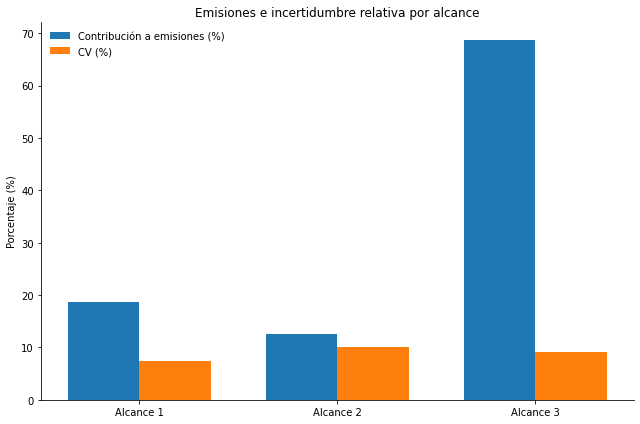

In [54]:
fig, ax = plt.subplots(figsize=(9, 6))

posiciones = np.arange(len(tabla_alcances))
ancho = 0.36

ax.bar(
    posiciones - ancho / 2,
    tabla_alcances["emision_pct_total"],
    width=ancho,
    label="Contribución a emisiones (%)",
)

ax.bar(
    posiciones + ancho / 2,
    tabla_alcances["cv_pct"],
    width=ancho,
    label="CV (%)",
)

ax.set_xticks(posiciones)
ax.set_xticklabels(tabla_alcances["alcance"])
ax.set_ylabel("Porcentaje (%)")
ax.set_title("Emisiones e incertidumbre relativa por alcance")
ax.legend(frameon=False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()